In [108]:
from datasets import load_dataset

dataset = load_dataset("m-ric/huggingface_doc")

print(dataset)
print(dataset["train"][0])

DatasetDict({
    train: Dataset({
        features: ['text', 'source'],
        num_rows: 2647
    })
})
{'text': ' Create an Endpoint\n\nAfter your first login, you will be directed to the [Endpoint creation page](https://ui.endpoints.huggingface.co/new). As an example, this guide will go through the steps to deploy [distilbert-base-uncased-finetuned-sst-2-english](https://huggingface.co/distilbert-base-uncased-finetuned-sst-2-english) for text classification. \n\n## 1. Enter the Hugging Face Repository ID and your desired endpoint name:\n\n<img src="https://raw.githubusercontent.com/huggingface/hf-endpoints-documentation/main/assets/1_repository.png" alt="select repository" />\n\n## 2. Select your Cloud Provider and region. Initially, only AWS will be available as a Cloud Provider with the `us-east-1` and `eu-west-1` regions. We will add Azure soon, and if you need to test Endpoints with other Cloud Providers or regions, please let us know.\n\n<img src="https://raw.githubusercontent

In [109]:
from datasets import load_dataset

dataset = load_dataset("m-ric/huggingface_doc")

print(dataset)

print("\nColumns:")
print(dataset["train"].column_names)

print("\nFirst Record:")
print(dataset["train"][0])

DatasetDict({
    train: Dataset({
        features: ['text', 'source'],
        num_rows: 2647
    })
})

Columns:
['text', 'source']

First Record:
{'text': ' Create an Endpoint\n\nAfter your first login, you will be directed to the [Endpoint creation page](https://ui.endpoints.huggingface.co/new). As an example, this guide will go through the steps to deploy [distilbert-base-uncased-finetuned-sst-2-english](https://huggingface.co/distilbert-base-uncased-finetuned-sst-2-english) for text classification. \n\n## 1. Enter the Hugging Face Repository ID and your desired endpoint name:\n\n<img src="https://raw.githubusercontent.com/huggingface/hf-endpoints-documentation/main/assets/1_repository.png" alt="select repository" />\n\n## 2. Select your Cloud Provider and region. Initially, only AWS will be available as a Cloud Provider with the `us-east-1` and `eu-west-1` regions. We will add Azure soon, and if you need to test Endpoints with other Cloud Providers or regions, please let us know

In [110]:
from datasets import load_dataset

dataset = load_dataset("m-ric/huggingface_doc")

print(dataset)

print("\nColumns:")
print(dataset["train"].column_names)

print("\nFirst Record:")
print(dataset["train"][0])

DatasetDict({
    train: Dataset({
        features: ['text', 'source'],
        num_rows: 2647
    })
})

Columns:
['text', 'source']

First Record:
{'text': ' Create an Endpoint\n\nAfter your first login, you will be directed to the [Endpoint creation page](https://ui.endpoints.huggingface.co/new). As an example, this guide will go through the steps to deploy [distilbert-base-uncased-finetuned-sst-2-english](https://huggingface.co/distilbert-base-uncased-finetuned-sst-2-english) for text classification. \n\n## 1. Enter the Hugging Face Repository ID and your desired endpoint name:\n\n<img src="https://raw.githubusercontent.com/huggingface/hf-endpoints-documentation/main/assets/1_repository.png" alt="select repository" />\n\n## 2. Select your Cloud Provider and region. Initially, only AWS will be available as a Cloud Provider with the `us-east-1` and `eu-west-1` regions. We will add Azure soon, and if you need to test Endpoints with other Cloud Providers or regions, please let us know

In [ ]:
import os
import pandas as pd
import numpy as np
from tqdm import tqdm
from datasets import load_dataset
from sentence_transformers import SentenceTransformer
from pymilvus import MilvusClient
from langchain_text_splitters import RecursiveCharacterTextSplitter

In [112]:
dataset = load_dataset(
    "m-ric/huggingface_doc"
)

docs = dataset["train"]

print("Documents:", len(docs))
print(docs[0])

Documents: 2647
{'text': ' Create an Endpoint\n\nAfter your first login, you will be directed to the [Endpoint creation page](https://ui.endpoints.huggingface.co/new). As an example, this guide will go through the steps to deploy [distilbert-base-uncased-finetuned-sst-2-english](https://huggingface.co/distilbert-base-uncased-finetuned-sst-2-english) for text classification. \n\n## 1. Enter the Hugging Face Repository ID and your desired endpoint name:\n\n<img src="https://raw.githubusercontent.com/huggingface/hf-endpoints-documentation/main/assets/1_repository.png" alt="select repository" />\n\n## 2. Select your Cloud Provider and region. Initially, only AWS will be available as a Cloud Provider with the `us-east-1` and `eu-west-1` regions. We will add Azure soon, and if you need to test Endpoints with other Cloud Providers or regions, please let us know.\n\n<img src="https://raw.githubusercontent.com/huggingface/hf-endpoints-documentation/main/assets/1_region.png" alt="select region" 

In [113]:
df = pd.DataFrame(docs)

df["length"] = df["text"].apply(len)

print(df["length"].describe())

count      2647.000000
mean       8079.177937
std       15850.725597
min          23.000000
25%        1915.000000
50%        4575.000000
75%        9249.500000
max      371057.000000
Name: length, dtype: float64


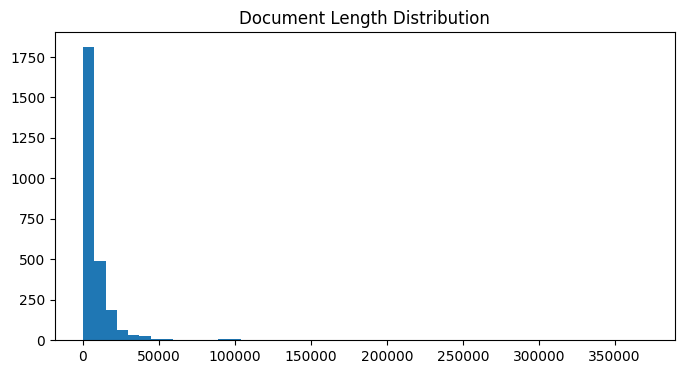

In [114]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,4))
plt.hist(df["length"], bins=50)
plt.title("Document Length Distribution")
plt.show()

In [115]:
CHUNK_SIZE = 1000
CHUNK_OVERLAP = 150

In [116]:
splitter = RecursiveCharacterTextSplitter(
    chunk_size=CHUNK_SIZE,
    chunk_overlap=CHUNK_OVERLAP
)

In [117]:
chunks = []

for row in tqdm(docs):

    text = row["text"]
    source = row["source"]

    split_docs = splitter.split_text(text)

    for idx, chunk in enumerate(split_docs):

        chunks.append({
            "chunk_id": len(chunks),
            "text": chunk,
            "source": source,
            "chunk_num": idx
        })

100%|██████████| 2647/2647 [00:00<00:00, 5531.93it/s]


In [118]:
print("Total Chunks:", len(chunks))

Total Chunks: 28826


In [119]:
embedding_model = SentenceTransformer(
    "BAAI/bge-small-en-v1.5"
)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

In [142]:
import os
texts = [c["text"] for c in chunks]

if os.path.exists("hf_embeddings.npy"):
    embeddings = np.load("hf_embeddings.npy")
else:
    embeddings = embedding_model.encode(
        texts,
        batch_size=128,
        show_progress_bar=True,
        normalize_embeddings=True
    )
    np.save("hf_embeddings.npy", embeddings)

Batches:   0%|          | 0/226 [00:00<?, ?it/s]

In [143]:
for i in range(len(chunks)):
    chunks[i]["embedding"] = embeddings[i]

In [144]:
import faiss

In [145]:
dimension = 384

index = faiss.IndexFlatIP(dimension)

index.add(
    np.array(embeddings).astype("float32")
)

In [146]:
nlist = 128

quantizer = faiss.IndexFlatIP(384)

index = faiss.IndexIVFFlat(
    quantizer,
    384,
    nlist,
    faiss.METRIC_INNER_PRODUCT
)

index.train(
    np.array(embeddings).astype("float32")
)

index.add(
    np.array(embeddings).astype("float32")
)

index.nprobe = 16
print(f"FAISS IVF-FLAT index built with {index.ntotal} vectors")

FAISS IVF-FLAT index built with 28826 vectors


In [147]:
chunk_texts = [c["text"] for c in chunks]

chunk_sources = [c["source"] for c in chunks]

In [148]:
def retrieve(question, top_k=15):

    q_embedding = embedding_model.encode(
        [question],
        normalize_embeddings=True
    )

    scores, indices = index.search(
        np.array(q_embedding).astype("float32"),
        top_k
    )

    results = []

    for score, idx in zip(scores[0], indices[0]):

        if idx == -1:
            continue

        results.append({
            "score": float(score),
            "source": chunks[idx]["source"],
            "text": chunks[idx]["text"]
        })

    return results

In [150]:
results = retrieve(
    "How do I create a Hugging Face endpoint?"
)

In [151]:
for r in results:

    print("="*100)

    print("Score:", r["score"])

    print("Source:", r["source"])

    print(r["text"][:500])

Score: 0.8115661144256592
Source: huggingface/blog/blob/main/inference-endpoints.md
### Now it's your turn!

Thanks to Inference Endpoints, you can deploy production-grade, scalable, secure endpoints in minutes, in just a few clicks. Why don't you [give it a try](https://ui.endpoints.huggingface.co/new)?

We have plenty of ideas to make the service even better, and we'd love to hear your feedback in the [Hugging Face forum](https://discuss.huggingface.co/).


Thank you for reading and have fun with Inference Endpoints!
Score: 0.8099856376647949
Source: huggingface/datasets-server/blob/main/docs/source/quick_start.mdx
Feel free to try out the API in [Postman](https://www.postman.com/huggingface/workspace/hugging-face-apis/documentation/23242779-d068584e-96d1-4d92-a703-7cb12cbd8053), [ReDoc](https://redocly.github.io/redoc/?url=https://datasets-server.huggingface.co/openapi.json) or [RapidAPI](https://rapidapi.com/hugging-face-hugging-face-default/api/hugging-face-datasets-api/). This qu

In [152]:
def build_context(results):

    context = ""

    for r in results:

        context += f"""
Source:
{r['source']}

Content:
{r['text']}

------------------------
"""

    return context

In [163]:
PROMPT = """
Answer the user's question using ONLY the provided context.

If the context contains relevant information,
answer using that information.

Provide a detailed explanation , not single line answers.

Do NOT require complete information.
Provide the best answer possible from the context.

Context:
{context}

Question:
{question}

Answer:
"""

In [165]:
question = "How do I create a Hugging Face endpoint?"

results = retrieve(
    question,
    top_k=3
)

context = build_context(results)

prompt = PROMPT.format(
    context=context,
    question=question
)

In [166]:
question = "How do I create a Hugging Face endpoint?"

results = retrieve(question, top_k=3)

for i, r in enumerate(results):

    print(f"\nResult {i+1}")
    print("Score:", r["score"])
    print("Source:", r["source"])
    print(r["text"][:300])


Result 1
Score: 0.8115661144256592
Source: huggingface/blog/blob/main/inference-endpoints.md
### Now it's your turn!

Thanks to Inference Endpoints, you can deploy production-grade, scalable, secure endpoints in minutes, in just a few clicks. Why don't you [give it a try](https://ui.endpoints.huggingface.co/new)?

We have plenty of ideas to make the service even better, and we'd love to hea

Result 2
Score: 0.8099856376647949
Source: huggingface/datasets-server/blob/main/docs/source/quick_start.mdx
Feel free to try out the API in [Postman](https://www.postman.com/huggingface/workspace/hugging-face-apis/documentation/23242779-d068584e-96d1-4d92-a703-7cb12cbd8053), [ReDoc](https://redocly.github.io/redoc/?url=https://datasets-server.huggingface.co/openapi.json) or [RapidAPI](https://rapidapi.com

Result 3
Score: 0.8054353594779968
Source: huggingface/hub-docs/blob/main/docs/hub/spaces-sdks-docker-shiny.md
-   Second, for the moment you must use the development version of [httpuv](https:

In [167]:
import requests

def rag_demo(question):

    results = retrieve(
        question,
        top_k=3
    )

    print("\nTOP RETRIEVAL RESULTS\n")

    for i, doc in enumerate(results, 1):
        print(f"\n[{i}]")
        print("Score:", round(doc["score"], 4))
        print("Source:", doc["source"])
        print(doc["text"][:400])
        print("-" * 80)

    context = build_context(
        results
    )

    prompt = PROMPT.format(
        context=context,
        question=question
    )

    response = requests.post(
        "http://localhost:11434/api/generate",
        json={
            "model": "mistral",
            "prompt": prompt,
            "stream": False
        }
    )

    answer = response.json()["response"]

    print("="*100)
    print("QUESTION:")
    print(question)

    print("\nANSWER:")
    print(answer)

    print("\nRETRIEVED SOURCES:")

    for r in results:
        print("-", r["source"])

    return answer

In [168]:
rag_demo(
    "How do I create a Hugging Face endpoint?"
)


TOP RETRIEVAL RESULTS


[1]
Score: 0.8116
Source: huggingface/blog/blob/main/inference-endpoints.md
### Now it's your turn!

Thanks to Inference Endpoints, you can deploy production-grade, scalable, secure endpoints in minutes, in just a few clicks. Why don't you [give it a try](https://ui.endpoints.huggingface.co/new)?

We have plenty of ideas to make the service even better, and we'd love to hear your feedback in the [Hugging Face forum](https://discuss.huggingface.co/).


Thank you for readin
--------------------------------------------------------------------------------

[2]
Score: 0.81
Source: huggingface/datasets-server/blob/main/docs/source/quick_start.mdx
Feel free to try out the API in [Postman](https://www.postman.com/huggingface/workspace/hugging-face-apis/documentation/23242779-d068584e-96d1-4d92-a703-7cb12cbd8053), [ReDoc](https://redocly.github.io/redoc/?url=https://datasets-server.huggingface.co/openapi.json) or [RapidAPI](https://rapidapi.com/hugging-face-hugging-face

" To create a Hugging Face endpoint, you can utilize the Inference Endpoints service provided by Hugging Face. Here's a step-by-step guide to help you get started:\n\n1. Go to the Inference Endpoints UI: [ui.endpoints.huggingface.co/new](https://ui.endpoints.huggingface.co/new).\n\n2. Follow the instructions provided on the platform to deploy a production-grade, scalable, secure endpoint in just a few clicks.\n\nKeep in mind that you can find more information and ideas to make the service even better in the Hugging Face forum at [discuss.huggingface.co](https://discuss.huggingface.co/).\n\nFor programmatic access, you may also want to explore other tools like Postman, ReDoc, or RapidAPI mentioned in the quick start guide for the Hugging Face Datasets API: [huggingface/datasets-server/blob/main/docs/source/quick_start.mdx](https://huggingface/datasets-server/blob/main/docs/source/quick_start.mdx).\n\nLastly, if you encounter issues with app timeouts on Hugging Face, it is recommended to

In [160]:
rag_demo(
    "How do I login to Hugging Face Hub?"
)


TOP RETRIEVAL RESULTS


[1]
Score: 0.8679
Source: huggingface/hub-docs/blob/main/docs/hub/models-adding-libraries.md
Username: 
   Password:
   ```

3. Alternatively, if you prefer working from a Jupyter or Colaboratory notebook, login with `notebook_login`:

   ```python
   >>> from huggingface_hub import notebook_login
   >>> notebook_login()
   ```

   `notebook_login` will launch a widget in your notebook from which you can enter your Hugging Face credentials.

## Download files from the Hub

Integration all
--------------------------------------------------------------------------------

[2]
Score: 0.8597
Source: huggingface/transformers/blob/main/examples/flax/README.md
A few notes on this integration:

- you will need to be logged in to the Hugging Face website locally for it to work, the easiest way to achieve this is to run `huggingface-cli login` and then type your username and password when prompted. You can also pass along your authentication token with the `--hub_token` a

" To log in to Hugging Face Hub, you have several options depending on your environment:\n\n1. If you're working from a Jupyter or Colab notebook, use the `notebook_login` function from the `huggingface_hub` package:\n\n   ```python\n   >>> from huggingface_hub import notebook_login\n   >>> notebook_login()\n   ```\n\n2. If you're working in a terminal or command line, use the `huggingface-cli login` command:\n\n   ```bash\n   $ huggingface-cli login\n   # ...follow the prompts\n   ```"

In [ ]:
rag_demo(
    "What cloud providers are supported?"
)

QUESTION:
What cloud providers are supported?

ANSWER:
 Insufficient information in documentation. The provided context only mentions Google Cloud (GCP) as the cloud provider used for deploying transformers. No other cloud providers are explicitly mentioned or confirmed to be supported.

RETRIEVED SOURCES:
- huggingface/blog/blob/main/how-to-deploy-a-pipeline-to-google-clouds.md
- huggingface/blog/blob/main/deploy-tfserving-kubernetes.md
- huggingface/blog/blob/main/habana-gaudi-2-benchmark.md
- huggingface/blog/blob/main/how-to-deploy-a-pipeline-to-google-clouds.md
- huggingface/blog/blob/main/deploy-tfserving-kubernetes.md


' Insufficient information in documentation. The provided context only mentions Google Cloud (GCP) as the cloud provider used for deploying transformers. No other cloud providers are explicitly mentioned or confirmed to be supported.'

In [ ]:
import faiss
import pickle

faiss.write_index(
    index,
    "hf_docs_ivf_flat.index"
)

with open(
    "hf_metadata.pkl",
    "wb"
) as f:

    pickle.dump(
        {
            "texts": chunk_texts,
            "sources": chunk_sources
        },
        f
    )

print("Artifacts saved.")

Artifacts saved.
